In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,KFold,cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error


test_processed = pd.read_csv('../data/processed/test_processed.csv')
train_processed = pd.read_csv('../data/processed/train_processed.csv')

X_train = train_processed.drop(columns=["SalePrice"])
y = np.log(train_processed["SalePrice"])

In [10]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")
kf = KFold(n_splits=5,shuffle=True,random_state=42)
base_score = -cross_val_score(baseline_model,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")
print(base_score)

[0.41059629 0.38878184 0.38085236 0.42653923 0.38966776]


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

random_forest = RandomForestRegressor(n_estimators=100,random_state=42)
random_forest_score = -cross_val_score(random_forest,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")

knn = Pipeline([('scaler', StandardScaler()),('knn', KNeighborsRegressor(n_neighbors=5))])
knn_score = -cross_val_score(knn,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")

linear_regression = LinearRegression()
linear_regression_score = -cross_val_score(linear_regression,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")

print(f"Random forest cross validation score {random_forest_score}") 
print(f"KNN cross validation score {knn_score}") 
print(f"Linear regression cross validation score {linear_regression_score}") 

Random forest cross validation score [0.14051303 0.13040124 0.14109879 0.13821673 0.12749137]
KNN cross validation score [0.20986605 0.19543375 0.18028179 0.20609368 0.1772126 ]
Linear regression cross validation score [0.13238526 0.13867601 0.12403131 0.12909869 0.1096811 ]


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge = Pipeline([('scaler',StandardScaler()),('ridge',Ridge())])
param_grid = {
    'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
grid_search = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train , y)

print("Best parameters:", grid_search.best_params_)
# print("Best RMSE:", -grid_search.best_score_)

ridge = grid_search.best_estimator_
ridge_score = -cross_val_score(ridge,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")
print(f"Ridge cross validation score {ridge_score}") 



Best parameters: {'ridge__alpha': 100}
Best RMSE: 0.11977876780399073
Ridge cross validation score [0.1228016  0.12749393 0.11857504 0.12449829 0.10552499]


In [14]:
comparison = pd.DataFrame({
    'Model': ['Dummy', 'Random Forest', 'KNN', 'Linear Regression', 'Ridge'],
    'CV1': [base_score[0], random_forest_score[0], knn_score[0],linear_regression_score[0], ridge_score[0]],
    'CV2': [base_score[1], random_forest_score[1], knn_score[1],linear_regression_score[1], ridge_score[1] ],
    'CV3': [base_score[2], random_forest_score[2], knn_score[2],linear_regression_score[2], ridge_score[2]],
    'CV4': [base_score[3], random_forest_score[3], knn_score[3],linear_regression_score[3], ridge_score[3]],
    'CV5': [base_score[4], random_forest_score[4], knn_score[4],linear_regression_score[4], ridge_score[4]],
    'CV_mean':[base_score.mean(),random_forest_score.mean(),knn_score.mean(),linear_regression_score.mean(),ridge_score.mean()]
})
comparison.to_csv('../results/model_comparison.csv',index=False )
comparison

,Model,CV1,CV2,CV3,CV4,CV5,CV_mean
0,Dummy,0.410596,0.388782,0.380852,0.426539,0.389668,0.399287
1,Random Forest,0.140513,0.130401,0.141099,0.138217,0.127491,0.135544
2,KNN,0.209866,0.195434,0.180282,0.206094,0.177213,0.193778
3,Linear Regression,0.132385,0.138676,0.124031,0.129099,0.109681,0.126774
4,Ridge,0.122802,0.127494,0.118575,0.124498,0.105525,0.119779


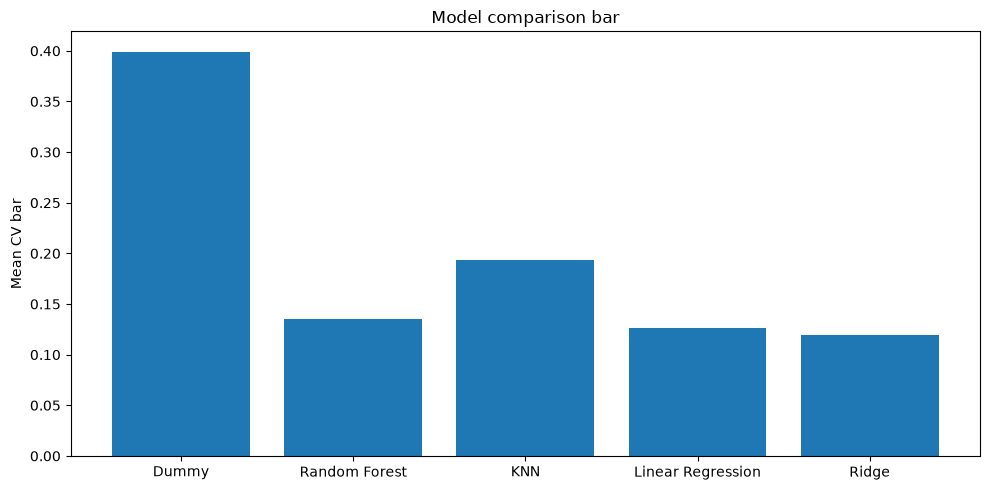

In [15]:
plt.figure(figsize=(10,5))
plt.bar(comparison['Model'],comparison['CV_mean'])
plt.ylabel('Mean CV bar')
plt.title('Model comparison bar')
plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import cross_val_predict

oof_predictions = cross_val_predict(
    ridge,
    X_train,
    y,
    cv=kf
)
oof_errors = y - oof_predictions
largest_errors = oof_errors.abs().sort_values(ascending=False)
largest_errors.head(10)

631     0.751382
462     0.674759
88      0.665724
1322    0.635705
967     0.601058
410     0.564381
30      0.539485
587     0.536139
1441    0.532885
969     0.526214
Name: SalePrice, dtype: float64

In [ ]:
test = pd.read_csv("../data/raw/test.csv")
ridge.fit(X_train,y)
prediction = ridge.predict(test_processed)
prediction = np.exp(prediction)
submission = pd.DataFrame({'Id': test['Id'],'SalePrice': prediction})
submission.to_csv('../submissions/submission_ridge.csv', index=False)
# prev_submission = pd.read_csv("../submissions/submission_ridge.csv")
# assert list(prev_submission) == list(submission)